**Analisis dan Implementasi Filter Digital FIR (Hamming & Blackman) dan IIR (Butterworth & Chebyshev) untuk Noise Reduction pada Sinyal Audio**

Tujuan

1. Mendesain dan mengimplementasikan filter digital FIR menggunakan metode windowing (Hamming dan Blackman) pada sinyal audio yang mengandung noise.
2. Mendesain dan mengimplementasikan filter digital IIR (Butterworth dan Chebyshev) sebagai pembanding dalam proses noise reduction.
3. Menganalisis karakteristik respon frekuensi dari masing-masing filter melalui magnitude response dan phase response.
4. Mengevaluasi performa setiap filter menggunakan SNR, RMS, spectral centroid, FFT, dan visualisasi domain waktu.
5. Melakukan analisis subjektif melalui pendengaran untuk mengetahui kualitas audio setelah proses filtering.
6. Menentukan filter yang paling optimal berdasarkan gabungan analisis objektif dan subjektif.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import filtfilt, sosfiltfilt, firwin, sosfreqz, freqz
from scipy.fft import fft, fftfreq
import soundfile as sf
from IPython.display import Audio

1. Load Audio

In [ ]:
audio_path = "PSD AUDIO NEW.wav"
clean, fs = sf.read(audio_path)

#mengkoversi stereo ke mono
if clean.ndim > 1:
    clean = clean.mean(axis=1)

t = np.arange(len(clean)) / fs
print("Sampling Rate:", fs, "Hz")

# optional playback in notebook
Audio(audio_path)

Sampling Rate: 48000 Hz


2. Analisis Frekuensi Dominan

In [ ]:
N = len(clean)
fft_values = np.abs(fft(clean))
freqs = fftfreq(N, 1/fs)
mask = freqs >= 0
freqs_pos = freqs[mask]
fft_pos = fft_values[mask]
idx = np.argmax(fft_pos)
dominant_freq = freqs_pos[idx]
print("Frekuensi Dominan Utama: {:.2f} Hz".format(dominant_freq))

Frekuensi Dominan Utama: 507.10 Hz


3. Penambahan Noise

In [ ]:
noise_level = 0.06
noise = noise_level * np.random.randn(len(clean))
noisy = clean + noise
sf.write("noisy.wav", noisy, fs)
Audio("noisy.wav")

4. Menentukan parameter filter (Cutoff & Bandpass)

In [ ]:
nyq = fs / 2.0

cutoff_lp_hz = 1000.0
norm_cutoff_lp = cutoff_lp_hz / nyq

bp_low_hz = max(200.0, dominant_freq - 160.0)
bp_high_hz = dominant_freq + 200.0
print("Using band-pass: {:.1f} - {:.1f} Hz".format(bp_low_hz, bp_high_hz))

Using band-pass: 347.1 - 707.1 Hz


5. Desain filter FIR dan IIR

In [ ]:
numtaps_fir_lp = 81
numtaps_fir_bp = 201

#Window Hamming
fir_hamming_lp = firwin(numtaps_fir_lp, norm_cutoff_lp, window="hamming")
fir_hamming_bp = firwin(numtaps_fir_bp, [bp_low_hz/nyq, bp_high_hz/nyq],pass_zero=False, window='hamming')

#Blackman
fir_blackman_lp = firwin(numtaps_fir_lp, norm_cutoff_lp, window="blackman")
fir_blackman_bp = firwin(numtaps_fir_bp, [bp_low_hz/nyq, bp_high_hz/nyq], pass_zero=False, window='blackman')

In [ ]:
iir_order = 4

#IIR Butterworth (LP & BP)
sos_iir_butter_lp = signal.butter(iir_order, norm_cutoff_lp, btype='low', output='sos')
sos_iir_butter_bp = signal.butter(iir_order, [bp_low_hz/nyq, bp_high_hz/nyq], btype='band', output='sos')

# IIR Chebyshev Type 1
sos_iir_cheby_lp = signal.cheby1(iir_order, 1, norm_cutoff_lp, btype='low', output='sos')
sos_iir_cheby_bp = signal.cheby1(iir_order, 1, [bp_low_hz/nyq, bp_high_hz/nyq], btype='band', output='sos')

6. Proses Filtering FIR & IIR

In [ ]:
#Hamming
out_fir_hamming_lp = filtfilt(fir_hamming_lp, [1.0], noisy)
out_fir_hamming_bp = filtfilt(fir_hamming_bp, [1.0], noisy)

#Blackman
out_fir_blackman_lp = filtfilt(fir_blackman_lp, [1.0], noisy)
out_fir_blackman_bp = filtfilt(fir_blackman_bp, [1.0], noisy)

In [ ]:
#Butterworth
out_iir_butter_lp = sosfiltfilt(sos_iir_butter_lp, noisy)
out_iir_butter_bp = sosfiltfilt(sos_iir_butter_bp, noisy)

#IIR Chebyshev Type 1
out_iir_cheby_lp = sosfiltfilt(sos_iir_cheby_lp, noisy)
out_iir_cheby_bp = sosfiltfilt(sos_iir_cheby_bp, noisy)

7. Menyimpan Hasil audio filter

In [ ]:
sf.write("fir_hamming_lp.wav", out_fir_hamming_lp, fs)
sf.write("fir_hamming_bp.wav", out_fir_hamming_bp, fs)
sf.write("fir_blackman_lp.wav", out_fir_blackman_lp, fs)
sf.write("fir_blackman_bp.wav", out_fir_blackman_bp, fs)

sf.write("iir_butter_lp.wav", out_iir_butter_lp, fs)
sf.write("iir_butter_bp.wav", out_iir_butter_bp, fs)
sf.write("iir_cheby_lp.wav", out_iir_cheby_lp, fs)
sf.write("iir_cheby_bp.wav", out_iir_cheby_bp, fs)

In [ ]:
Audio("fir_hamming_lp.wav")

In [ ]:
Audio("fir_hamming_bp.wav")

In [ ]:
Audio("fir_blackman_lp.wav")

In [ ]:
Audio("fir_blackman_bp.wav")

In [ ]:
Audio("iir_butter_lp.wav")

In [ ]:
Audio("iir_butter_bp.wav")

In [ ]:
Audio("iir_cheby_lp.wav")

In [ ]:
Audio("iir_cheby_bp.wav")

8. Visualisasi hasil filtering

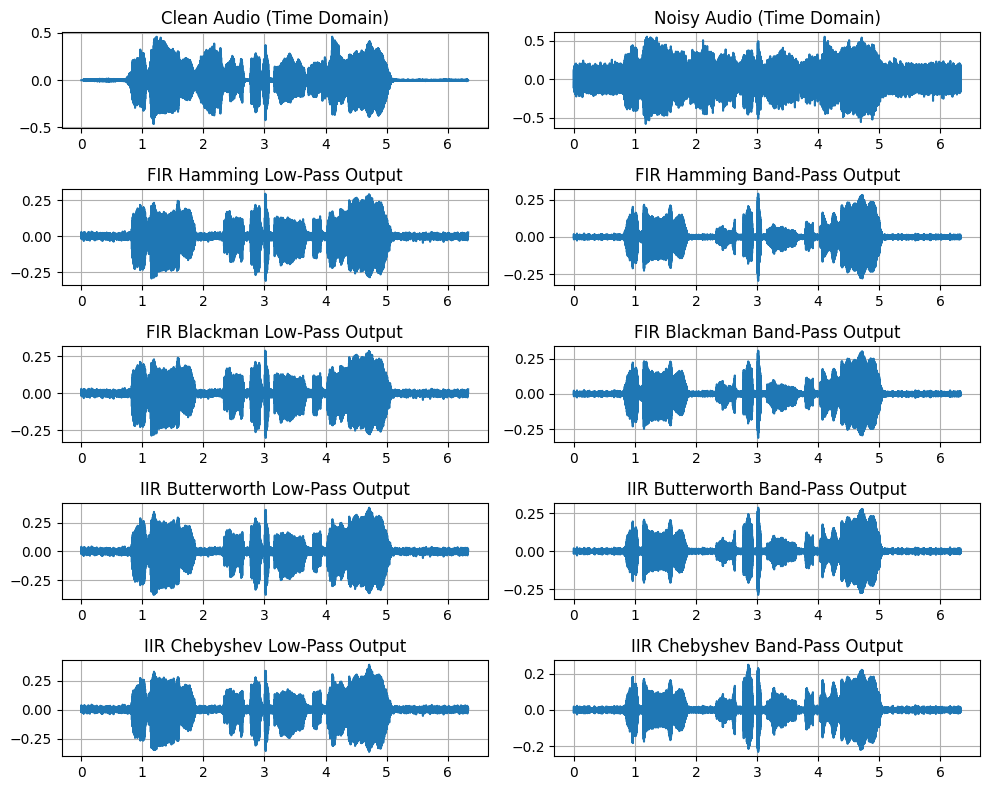

In [ ]:
# Visualisasi hasil satuan

plt.figure(figsize=(10,8))

plt.subplot(5,2,1)
plt.plot(t, clean)
plt.title("Clean Audio (Time Domain)")
plt.grid(True)

plt.subplot(5,2,2)
plt.plot(t, noisy)
plt.title("Noisy Audio (Time Domain)")
plt.grid(True)

plt.subplot(5,2,3)
plt.plot(t, out_fir_hamming_lp)
plt.title("FIR Hamming Low-Pass Output")
plt.grid(True)

plt.subplot(5,2,4)
plt.plot(t, out_fir_hamming_bp)
plt.title("FIR Hamming Band-Pass Output")
plt.grid(True)

plt.subplot(5,2,5)
plt.plot(t, out_fir_blackman_lp)
plt.title("FIR Blackman Low-Pass Output")
plt.grid(True)

plt.subplot(5,2,6)
plt.plot(t, out_fir_blackman_bp)
plt.title("FIR Blackman Band-Pass Output")
plt.grid(True)

plt.subplot(5,2,7)
plt.plot(t, out_iir_butter_lp)
plt.title("IIR Butterworth Low-Pass Output")
plt.grid(True)

plt.subplot(5,2,8)
plt.plot(t, out_iir_butter_bp)
plt.title("IIR Butterworth Band-Pass Output")
plt.grid(True)

plt.subplot(5,2,9)
plt.plot(t, out_iir_cheby_lp)
plt.title("IIR Chebyshev Low-Pass Output")
plt.grid(True)

plt.subplot(5,2,10)
plt.plot(t, out_iir_cheby_bp)
plt.title("IIR Chebyshev Band-Pass Output")
plt.grid(True)

plt.tight_layout()
plt.show()

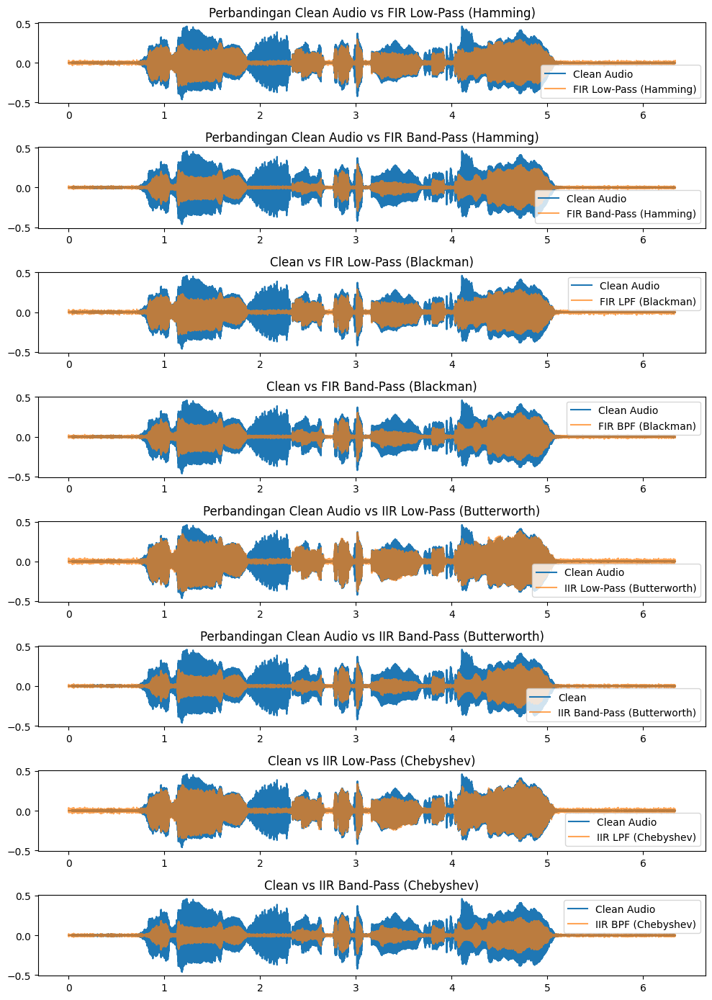

In [ ]:
#visualisasi hasil perbandingan

plt.figure(figsize=(10,14))

plt.subplot(8,1,1)
plt.plot(t, clean, label="Clean Audio")
plt.plot(t, out_fir_hamming_lp, label="FIR Low-Pass (Hamming)", alpha=0.7)
plt.title("Perbandingan Clean Audio vs FIR Low-Pass (Hamming)")
plt.legend()

plt.subplot(8,1,2)
plt.plot(t, clean, label="Clean Audio")
plt.plot(t, out_fir_hamming_bp, label="FIR Band-Pass (Hamming)", alpha=0.7)
plt.title("Perbandingan Clean Audio vs FIR Band-Pass (Hamming)")
plt.legend()

plt.subplot(8,1,3)
plt.plot(t, clean, label="Clean Audio")
plt.plot(t, out_fir_blackman_lp, label="FIR LPF (Blackman)", alpha=0.7)
plt.title("Clean vs FIR Low-Pass (Blackman)")
plt.legend()

plt.subplot(8,1,4)
plt.plot(t, clean, label="Clean Audio")
plt.plot(t, out_fir_blackman_bp, label="FIR BPF (Blackman)", alpha=0.7)
plt.title("Clean vs FIR Band-Pass (Blackman)")
plt.legend()

plt.subplot(8,1,5)
plt.plot(t, clean, label="Clean Audio")
plt.plot(t, out_iir_butter_lp, label="IIR Low-Pass (Butterworth)", alpha=0.7)
plt.title("Perbandingan Clean Audio vs IIR Low-Pass (Butterworth)")
plt.legend()

plt.subplot(8,1,6)
plt.plot(t, clean, label="Clean")
plt.plot(t, out_iir_butter_bp, label="IIR Band-Pass (Butterworth)", alpha=0.7)
plt.title("Perbandingan Clean Audio vs IIR Band-Pass (Butterworth)")
plt.legend()

plt.subplot(8,1,7)
plt.plot(t, clean, label="Clean Audio")
plt.plot(t, out_iir_cheby_lp, label="IIR LPF (Chebyshev)", alpha=0.7)
plt.title("Clean vs IIR Low-Pass (Chebyshev)")
plt.legend()

plt.subplot(8,1,8)
plt.plot(t, clean, label="Clean Audio")
plt.plot(t, out_iir_cheby_bp, label="IIR BPF (Chebyshev)", alpha=0.7)
plt.title("Clean vs IIR Band-Pass (Chebyshev)")
plt.legend()

plt.tight_layout()
plt.show()

9. SNR, RMS & Spectral Centroid

In [ ]:
def rms(x): return np.sqrt(np.mean(x**2))

def snr_ref(reference, processed):
    noise_component = reference - processed
    return 10 * np.log10(np.sum(reference**2) / (np.sum(noise_component**2) + 1e-12))

def spectral_centroid(x, fs):
    X = np.abs(fft(x))
    f = fftfreq(len(x), 1/fs)
    pos = f > 0
    return np.sum(f[pos] * X[pos]) / (np.sum(X[pos]) + 1e-12)

In [ ]:
results_base = {
    "Metode": ["Clean", "Noisy"],
    "SNR (dB)": [np.nan, snr_ref(clean, noisy)],
    "RMS": [rms(clean), rms(noisy)],
    "Spectral Centroid (Hz)": [
        spectral_centroid(clean, fs),
        spectral_centroid(noisy, fs)
    ]
}

df_base = pd.DataFrame(results_base).round(2)
df_base

,Metode,SNR (dB),RMS,Spectral Centroid (Hz)
0,Clean,NaN,0.09,4993.35
1,Noisy,3.93,0.11,9923.66


In [ ]:
results_fir_hamming = {
    "Metode": ["FIR Low-Pass (Hamming)", "FIR Band-Pass (Hamming)"],
    "SNR (dB)": [
        snr_ref(clean, out_fir_hamming_lp),
        snr_ref(clean, out_fir_hamming_bp),
    ],
    "RMS": [
        rms(out_fir_hamming_lp),
        rms(out_fir_hamming_bp),
    ],
    "Spectral Centroid (Hz)": [
        spectral_centroid(out_fir_hamming_lp, fs),
        spectral_centroid(out_fir_hamming_bp, fs)
    ]
}

df_fir_hamming = pd.DataFrame(results_fir_hamming).round(2)
df_fir_hamming

,Metode,SNR (dB),RMS,Spectral Centroid (Hz)
0,FIR Low-Pass (Hamming),6.68,0.07,525.27
1,FIR Band-Pass (Hamming),3.34,0.06,516.57


In [ ]:
results_fir_blackman = {
    "Metode": ["FIR Low-Pass (Blackman)", "FIR Band-Pass (Blackman)"],
    "SNR (dB)": [
        snr_ref(clean, out_fir_blackman_lp),
        snr_ref(clean, out_fir_blackman_bp),
    ],
    "RMS": [
        rms(out_fir_blackman_lp),
        rms(out_fir_blackman_bp),
    ],
    "Spectral Centroid (Hz)": [
        spectral_centroid(out_fir_blackman_lp, fs),
        spectral_centroid(out_fir_blackman_bp, fs)
    ]
}

df_fir_hamming = pd.DataFrame(results_fir_blackman).round(2)
df_fir_hamming

,Metode,SNR (dB),RMS,Spectral Centroid (Hz)
0,FIR Low-Pass (Blackman),6.66,0.07,537.73
1,FIR Band-Pass (Blackman),4.25,0.06,515.05


In [ ]:
results_iir_butter = {
    "Metode": ["IIR Low-Pass (Butterworth)", "IIR Band-Pass (Butterworth)"],
    "SNR (dB)": [
        snr_ref(clean, out_iir_butter_lp),
        snr_ref(clean, out_iir_butter_bp),
    ],
    "RMS": [
        rms(out_iir_butter_lp),
        rms(out_iir_butter_bp),
    ],
    "Spectral Centroid (Hz)": [
        spectral_centroid(out_iir_butter_lp, fs),
        spectral_centroid(out_iir_butter_bp, fs)
    ]
}

df_iir_butter = pd.DataFrame(results_iir_butter).round(2)
df_iir_butter

,Metode,SNR (dB),RMS,Spectral Centroid (Hz)
0,IIR Low-Pass (Butterworth),8.26,0.09,554.89
1,IIR Band-Pass (Butterworth),2.47,0.06,562.64


In [ ]:
results_iir_cheby = {
    "Metode": ["IIR Low-Pass (Chebyshev)", "IIR Band-Pass (Chebyshev)"],
    "SNR (dB)": [
        snr_ref(clean, out_iir_cheby_lp),
        snr_ref(clean, out_iir_cheby_bp),
    ],
    "RMS": [
        rms(out_iir_cheby_lp),
        rms(out_iir_cheby_bp),
    ],
    "Spectral Centroid (Hz)": [
        spectral_centroid(out_iir_cheby_lp, fs),
        spectral_centroid(out_iir_cheby_bp, fs)
    ]
}

df_iir_cheby = pd.DataFrame(results_iir_cheby).round(2)
df_iir_cheby

,Metode,SNR (dB),RMS,Spectral Centroid (Hz)
0,IIR Low-Pass (Chebyshev),8.39,0.08,571.98
1,IIR Band-Pass (Chebyshev),2.27,0.05,567.56


10. Fungsi Plot FFT

In [ ]:
def plot_fft(sig, fs, title, xlim=8000):
    N = len(sig)
    X = np.abs(fft(sig))
    f = fftfreq(N, 1/fs)
    mask = (f >= 0) & (f <= fs/2)
    plt.figure(figsize=(8,3))
    plt.plot(f[mask], 20*np.log10(X[mask] + 1e-12))
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.xlim(0, xlim)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

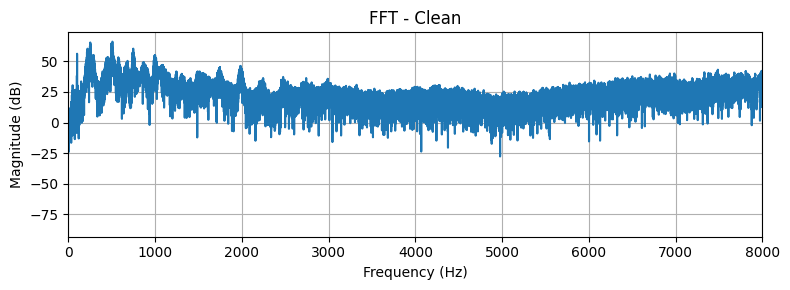

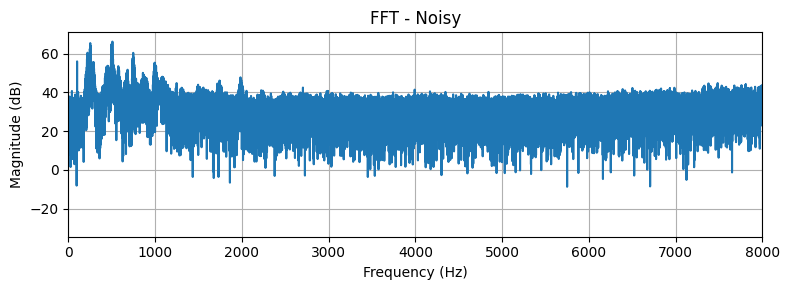

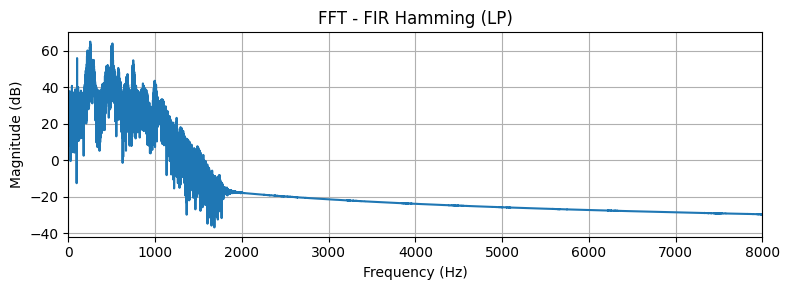

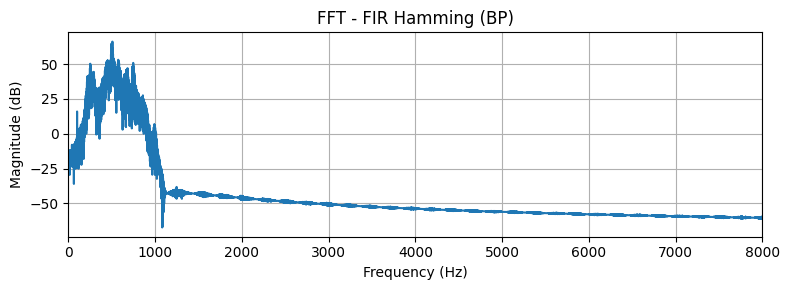

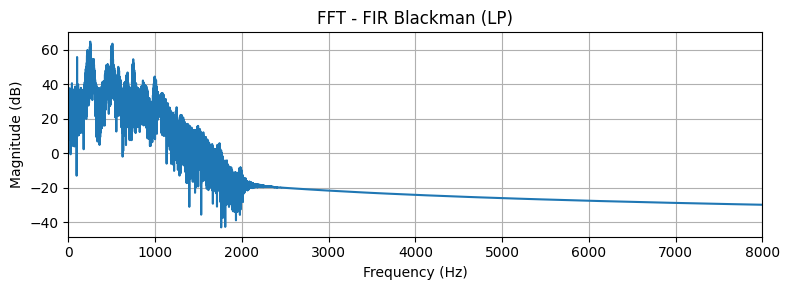

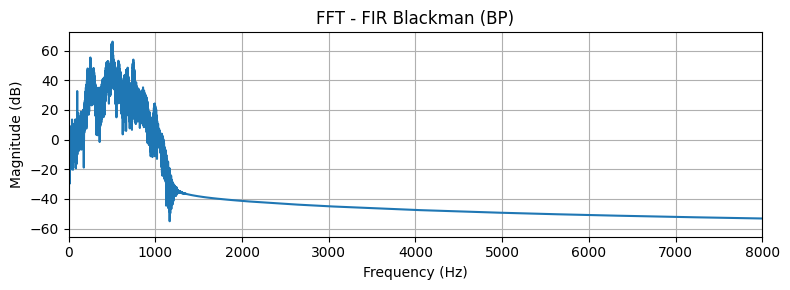

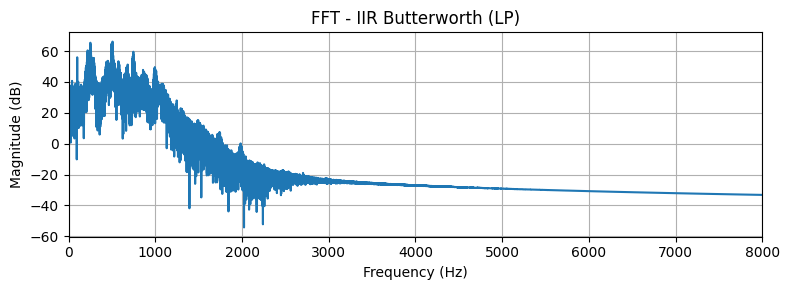

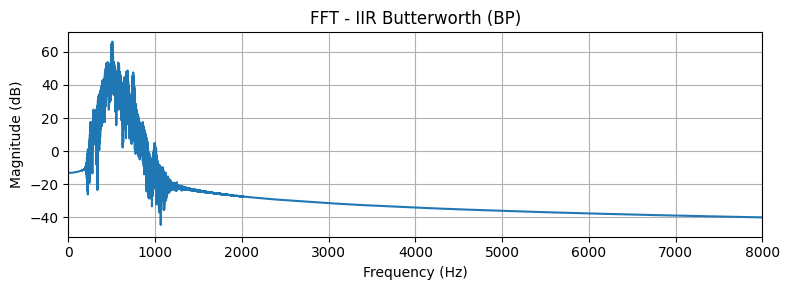

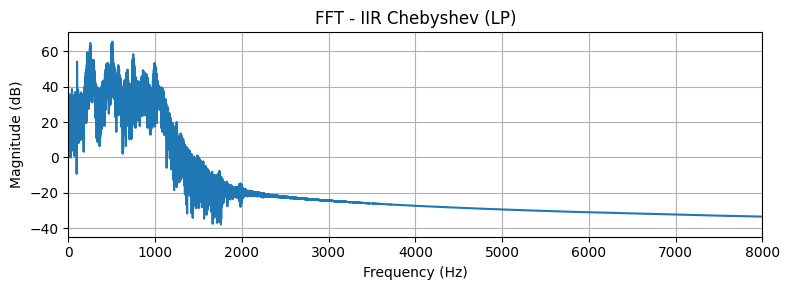

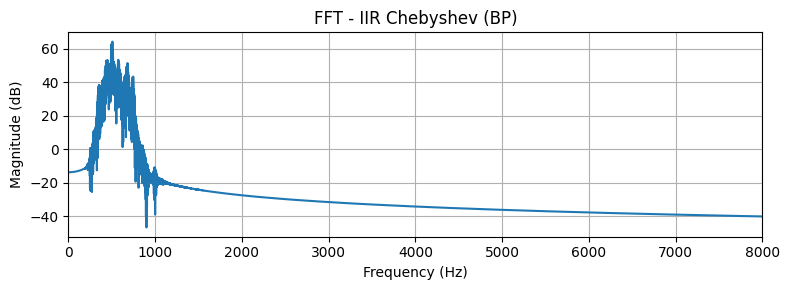

In [ ]:
#Analisis FFT sebelum dan sesudah filtering
plot_fft(clean, fs, "FFT - Clean")
plot_fft(noisy, fs, "FFT - Noisy")

plot_fft(out_fir_hamming_lp, fs, "FFT - FIR Hamming (LP)")
plot_fft(out_fir_hamming_bp, fs, "FFT - FIR Hamming (BP)")

plot_fft(out_fir_blackman_lp, fs, "FFT - FIR Blackman (LP)")
plot_fft(out_fir_blackman_bp, fs, "FFT - FIR Blackman (BP)")

plot_fft(out_iir_butter_lp, fs, "FFT - IIR Butterworth (LP)")
plot_fft(out_iir_butter_bp, fs, "FFT - IIR Butterworth (BP)")

plot_fft(out_iir_cheby_lp, fs, "FFT - IIR Chebyshev (LP)")
plot_fft(out_iir_cheby_bp, fs, "FFT - IIR Chebyshev (BP)")

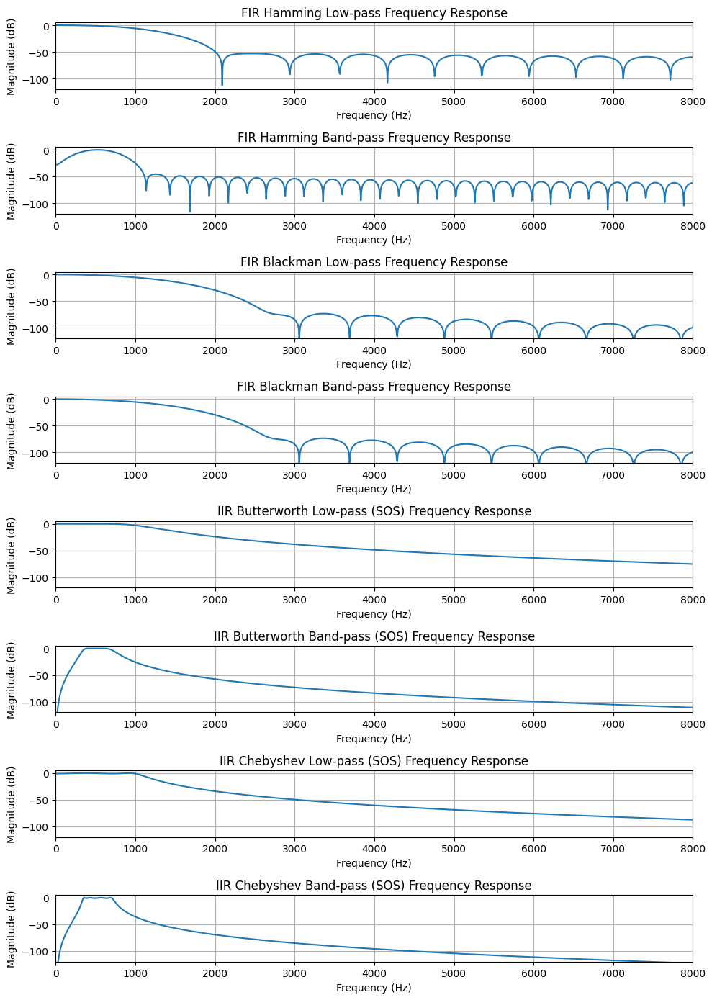

In [ ]:
#frekuensi response filter
plt.figure(figsize=(10,14))

w, h = freqz(fir_hamming_lp, worN=4096)
plt.subplot(8,1,1)
plt.plot((w/np.pi)*nyq, 20*np.log10(np.abs(h) + 1e-12))
plt.title("FIR Hamming Low-pass Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, 8000)
plt.ylim(-120,5)
plt.grid(True)

w, h = freqz(fir_hamming_bp, worN=4096)
plt.subplot(8,1,2)
plt.plot((w/np.pi)*nyq, 20*np.log10(np.abs(h) + 1e-12))
plt.title("FIR Hamming Band-pass Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, 8000)
plt.ylim(-120,5)
plt.grid(True)

w, h = freqz(fir_blackman_lp, worN=4096)
plt.subplot(8,1,3)
plt.plot((w/np.pi)*nyq, 20*np.log10(np.abs(h) + 1e-12))
plt.title("FIR Blackman Low-pass Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, 8000)
plt.ylim(-120,5)
plt.grid(True)

w, h = freqz(fir_blackman_lp, worN=4096)
plt.subplot(8,1,4)
plt.plot((w/np.pi)*nyq, 20*np.log10(np.abs(h) + 1e-12))
plt.title("FIR Blackman Band-pass Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, 8000)
plt.ylim(-120,5)
plt.grid(True)

w, h = sosfreqz(sos_iir_butter_lp, worN=4096, fs=fs)
plt.subplot(8,1,5)
plt.plot(w, 20*np.log10(np.abs(h) + 1e-12))
plt.title("IIR Butterworth Low-pass (SOS) Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0,8000)
plt.ylim(-120,5)
plt.grid(True)

w, h = sosfreqz(sos_iir_butter_bp, worN=4096, fs=fs)
plt.subplot(8,1,6)
plt.plot(w, 20*np.log10(np.abs(h) + 1e-12))
plt.title("IIR Butterworth Band-pass (SOS) Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0,8000); plt.ylim(-120,5)
plt.grid(True)

w, h = sosfreqz(sos_iir_cheby_lp, worN=4096, fs=fs)
plt.subplot(8,1,7)
plt.plot(w, 20*np.log10(np.abs(h) + 1e-12))
plt.title("IIR Chebyshev Low-pass (SOS) Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0,8000)
plt.ylim(-120,5)
plt.grid(True)

w, h = sosfreqz(sos_iir_cheby_bp, worN=4096, fs=fs)
plt.subplot(8,1,8)
plt.plot(w, 20*np.log10(np.abs(h) + 1e-12))
plt.title("IIR Chebyshev Band-pass (SOS) Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0,8000); plt.ylim(-120,5)
plt.grid(True)


plt.tight_layout()
plt.show()

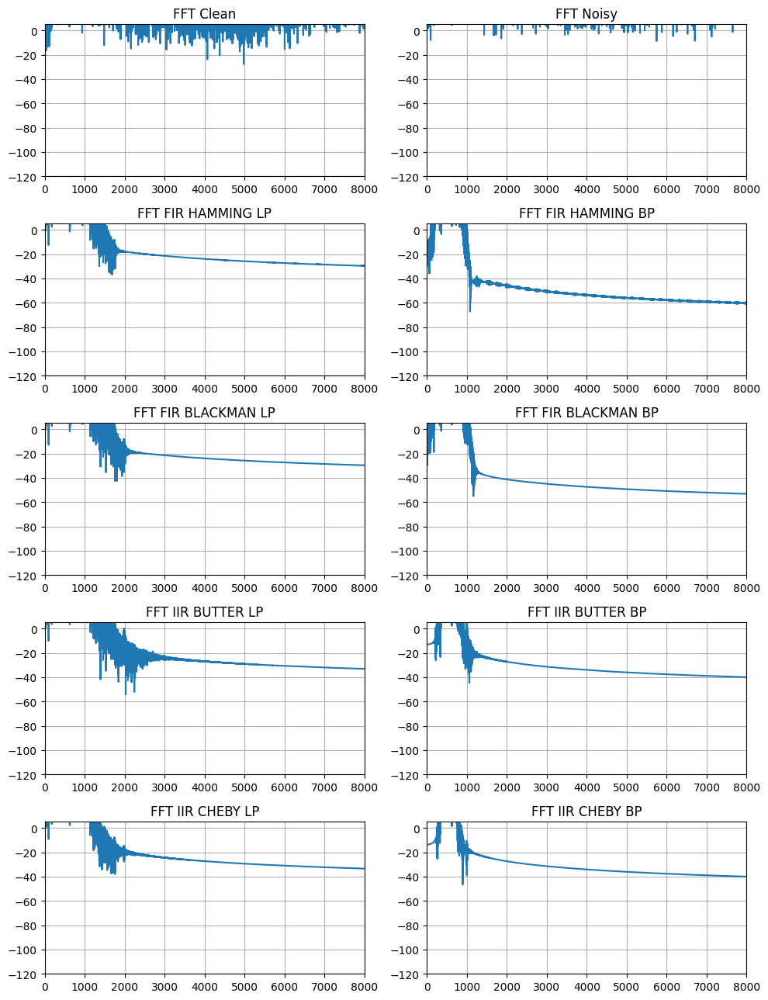

In [ ]:
#perbandingan FFT semua sinyal
def plot_fft_subplot(sig, fs, pos, title, xlim=8000):
    N = len(sig)
    X = np.abs(fft(sig))
    f = fftfreq(N, 1/fs)
    mask = (f >= 0) & (f <= fs/2)
    plt.subplot(5, 2, pos)
    plt.plot(f[mask], 20*np.log10(X[mask] + 1e-12))
    plt.title(title)
    plt.xlim(0,xlim)
    plt.ylim(-120,5)
    plt.grid(True)

plt.figure(figsize=(10,13))
plot_fft_subplot(clean, fs, 1, "FFT Clean")
plot_fft_subplot(noisy, fs, 2, "FFT Noisy")
plot_fft_subplot(out_fir_hamming_lp, fs, 3, "FFT FIR HAMMING LP")
plot_fft_subplot(out_fir_hamming_bp, fs, 4, "FFT FIR HAMMING BP")
plot_fft_subplot(out_fir_blackman_lp, fs, 5, "FFT FIR BLACKMAN LP")
plot_fft_subplot(out_fir_blackman_bp, fs, 6, "FFT FIR BLACKMAN BP")
plot_fft_subplot(out_iir_butter_lp, fs, 7, "FFT IIR BUTTER LP")
plot_fft_subplot(out_iir_butter_bp, fs, 8, "FFT IIR BUTTER BP")
plot_fft_subplot(out_iir_cheby_lp, fs, 9, "FFT IIR CHEBY LP")
plot_fft_subplot(out_iir_cheby_bp, fs, 10, "FFT IIR CHEBY BP")

plt.tight_layout()
plt.show()